In [21]:
import numpy as np
import torch
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import cv2
from PIL import Image
from scripts.blazeface import BlazeFace, BlazeFaceWrapper
from scripts.postprocess import postprocess
from scripts.visualize import visualize
from PIL import Image
from PIL import ImageDraw

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
device

device(type='cuda', index=0)

In [6]:
path = "artefacts/blazeface.pth"
front_net = BlazeFace().to(device)
front_net.load_state_dict(torch.load(path))
front_net.eval()  

anchor_path = "artefacts/anchors.npy"
anchors = np.load(anchor_path)
anchors_tensor = torch.tensor(anchors).to(device).float()

model = BlazeFaceWrapper(front_net, anchors_tensor).to(device)
model.eval()
pass

In [7]:
img = Image.open("test_image.jpg").convert("RGB")
original_width, original_height = img.width, img.height
target_width, target_height = 128, 128
img_resized = img.resize((target_width, target_height))
img_tensor = torch.from_numpy(np.array(img_resized)).permute((2, 0, 1)).unsqueeze(0).to(device).float()

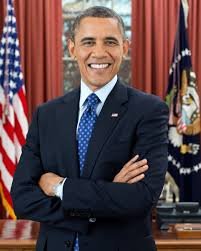

In [8]:
img

In [9]:
img_tensor.shape

torch.Size([1, 3, 128, 128])

In [10]:
with torch.no_grad():
    y = model(img_tensor)

In [11]:
y.shape

torch.Size([1, 896, 17])

In [13]:
output = y.cpu().numpy()

In [14]:
output.shape

(1, 896, 17)

In [15]:
detections = postprocess(
    output,
    min_score_thresh=0.5,
    min_suppression_threshold=0.3,
)

### Visualize

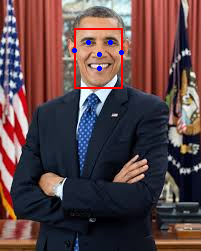

In [22]:
visualize(
    img,
    detections,
    target_width,
    target_height,
    original_width,
    original_height,
)